**Step 1:Load Dataset and summarize basic statistics**

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder

df = pd.read_csv("Titanic-Dataset.csv")
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [29]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Step 2 : Handle Missing Data**

In [30]:
print("Missing values before cleaning:")
print(df.isnull().sum())
df["Age"] = df["Age"].fillna(df["Age"].median())
if "Fare" in df.columns:
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0])
print("\nMissing values after cleaning selected columns:")
print(df[["Age", "Fare", "Embarked"]].isnull().sum())

Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing values after cleaning selected columns:
Age         0
Fare        0
Embarked    0
dtype: int64


**Step 3: Encode Categorical Variables**

In [31]:

label_encoder = LabelEncoder()
df["Sex_Encoded"] = label_encoder.fit_transform(df["Sex"])

print("Label Encoding:")
display(df[["Sex", "Sex_Encoded"]].head())

# One-Hot Encoding for Embarked
embarked_encoded = pd.get_dummies(
    df["Embarked"],
    prefix="Embarked",
    dtype=int)

df = pd.concat([df, embarked_encoded], axis=1)

print("One-Hot Encoding:")
display(df.head())

Label Encoding:


,Sex,Sex_Encoded
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1


One-Hot Encoding:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Sex_Encoded,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,0,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,0,0,0,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,0,0,1


****Mini Project 1****

**Titanic Survival Prediction:Data Cleaning Project**

**Objective**: Clean the Titanic dataset,encode categorical columns,visualize age distribution and export the cleaned dataset.

**Task 1**: Clean missing data

In [32]:

titanic = pd.read_csv("Titanic-Dataset.csv")

titanic["Age"] = titanic["Age"].fillna(
    titanic["Age"].median())

titanic["Fare"] = titanic["Fare"].fillna(
    titanic["Fare"].median())

titanic["Embarked"] = titanic["Embarked"].fillna(
    titanic["Embarked"].mode()[0])
titanic = titanic.drop(columns=["Cabin"])
print("Missing values after cleaning:")
print(titanic.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


**Task 2**: Encode Sex and Embarked columns

In [33]:

sex_encoder = LabelEncoder()
titanic["Sex"] = sex_encoder.fit_transform(titanic["Sex"])
titanic = pd.get_dummies(
    titanic,
    columns=["Embarked"],
    dtype=int)
display(titanic.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0,0,1


**Task 3**: Visualize age distribution

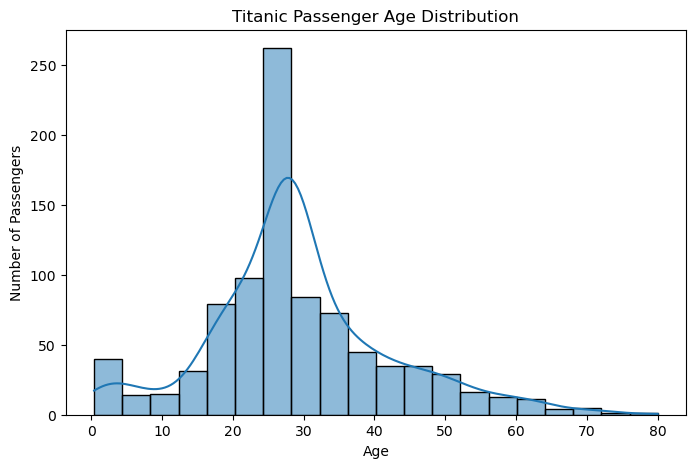

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=titanic,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Titanic Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

**Task 4** : Save the cleaned dataset as a new CSV

In [35]:
titanic.to_csv("Titanic_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [36]:
import os

print(os.path.exists("Titanic_Cleaned.csv"))
print(os.path.abspath("Titanic_Cleaned.csv"))

True
C:\Users\chirr\Downloads\week1\Titanic_Cleaned.csv
